In [1]:
import numpy as np
import matplotlib.pyplot as plt
# =============================================================================
# 1. A time-varying submodular family with a BRUTE-FORCE ground truth.
#    f_t(S) = alpha * sqrt(sum_{i in S} w_i)  -  sum_{i in S} b_t[i]
#      * sqrt(.) concave increasing, w_i>=0  -> first term submodular
#      * modular second term preserves submodularity
#      * f_t(emptyset)=0  (needed for the extended-domain Lovasz extension)
#    b_t[i] drifts in time so the minimiser MOVES (dynamic regret is nontrivial).
#    n is kept small so we can brute-force min_S f_t(S) and the best fixed set.
# =============================================================================
class DriftingSubmodular:
    def __init__(self, n=10, alpha=3.0, drift_amp=1.0, drift_period=400.0, seed=0):
        rng = np.random.default_rng(seed)
        self.n = n
        self.alpha = alpha
        self.w = rng.uniform(0.5, 1.5, size=n)          # concave-term weights
        self.base_b = rng.uniform(0.0, 1.0, size=n)     # baseline linear term
        self.amp = drift_amp
        self.period = drift_period
        self.phase = rng.uniform(0, 2*np.pi, size=n)
        # enumerate all subsets ONCE for the ground truth (n small)
        self.masks = ((np.arange(1 << n)[:, None] >> np.arange(n)[None, :]) & 1
                      ).astype(float)                    # (2^n, n)
        self.sqrt_w_all = np.sqrt(self.masks @ self.w)   # (2^n,) fixed in t
        self.t = 0

    def precompute(self, T, chunk=2000):
        """Cache b_t and the min curve; both are method- and seed-independent."""
        ts = np.arange(T)
        self._B = self.base_b[None, :] + self.amp*np.sin(
            2*np.pi*ts[:, None]/self.period + self.phase[None, :])
        mins = np.empty(T)
        for s in range(0, T, chunk):
            e = min(s+chunk, T)
            allv = self.alpha*self.sqrt_w_all[None, :] - self._B[s:e] @ self.masks.T
            mins[s:e] = allv.min(axis=1)
        self._mins = mins
        return mins

    def b(self, t):
        if getattr(self, "_B", None) is not None:
            return self._B[t]
        return self.base_b + self.amp*np.sin(2*np.pi*t/self.period + self.phase)

    def f(self, S_bin, t):
        S_bin = np.asarray(S_bin, dtype=float)
        return self.alpha*np.sqrt(S_bin @ self.w) - S_bin @ self.b(t)

    # ---- ground truth via brute force over all 2^n subsets ------------------
    def all_values(self, t):
        return self.alpha*self.sqrt_w_all - self.masks @ self.b(t)

    def min_value(self, t):
        if getattr(self, "_mins", None) is not None:
            return self._mins[t]
        return self.all_values(t).min()

    def range_bound(self, T):
        """Crude M = max_{t,S}|f_t(S)| over the horizon, for tuning eta,delta."""
        M = 0.0
        for t in range(0, T, max(1, T//200)):
            M = max(M, np.abs(self.all_values(t)).max())
        return M


# =============================================================================
# 2. Lovasz tools (independent of the notebook code).
# =============================================================================
def sort_desc(x):
    """Return permutation pi (indices) sorting x in DESCENDING order."""
    return np.argsort(-x, kind='stable')

def chain_sets(x):
    """B_0=empty ... B_n=[n] as binary vectors, following the descending sort."""
    n = len(x); pi = sort_desc(x)
    B = np.zeros((n+1, n))
    for k in range(1, n+1):
        B[k] = B[k-1]; B[k][pi[k-1]] = 1.0
    return B, pi

def lovasz_value(F, x):
    """f^L(x) via the sort formula; F is a callable set->value with F(empty)=0."""
    n = len(x); pi = sort_desc(x)
    val = 0.0; prev = np.zeros(n); fprev = 0.0
    for k in range(n):
        cur = prev.copy(); cur[pi[k]] = 1.0
        fcur = F(cur)
        val += x[pi[k]]*(fcur - fprev)
        prev, fprev = cur, fcur
    return val

def lovasz_subgradient(F, x):
    """Greedy/chain subgradient of f^L at x."""
    n = len(x); pi = sort_desc(x)
    g = np.zeros(n); prev = np.zeros(n); fprev = 0.0
    for k in range(n):
        cur = prev.copy(); cur[pi[k]] = 1.0
        fcur = F(cur)
        g[pi[k]] = fcur - fprev
        prev, fprev = cur, fcur
    return g

def threshold_set(x, tau):
    return (x > tau).astype(float)

def proj01(x):
    return np.clip(x, 0.0, 1.0)


# =============================================================================
# 3. Method A: Hazan-Kale Algorithm 3 (Bandit Submodular Subgradient Descent).
#    One play per update. Importance-weighted chain sampling + 1-sample
#    subgradient estimator. Reference: Hazan & Kale (2012), Alg 3.
# =============================================================================
class HazanKale:
    def __init__(self, n, eta, delta, x0=None, rng=None):
        self.n = n; self.eta = eta; self.delta = delta
        self.x = np.full(n, 0.5) if x0 is None else x0.copy()
        self.rng = rng or np.random.default_rng()
        self._pending = None

    def act(self):
        x = self.x; n = self.n
        pi = sort_desc(x)
        xs = x[pi]
        # convex-combination weights mu_k for chain sets B_0..B_n
        mu = np.zeros(n+1)
        mu[0] = 1 - xs[0]
        for k in range(1, n):
            mu[k] = xs[k-1] - xs[k]
        mu[n] = xs[n-1]
        rho = (1-self.delta)*mu + self.delta/(n+1)
        rho = np.clip(rho, 1e-12, None); rho /= rho.sum()
        i = self.rng.choice(n+1, p=rho)
        # build B_i
        S = np.zeros(n)
        if i > 0: S[pi[:i]] = 1.0
        self._pending = (i, pi, rho, S)
        return S

    def observe(self, cost):
        i, pi, rho, S = self._pending
        n = self.n
        g = np.zeros(n)
        if i == 0:
            g[pi[0]] = -cost/rho[0]
        elif i == n:
            g[pi[n-1]] = cost/rho[n]
        else:
            if self.rng.random() < 0.5:
                g[pi[i-1]] = 2*cost/rho[i]      # +1 branch, coord pi(i)
            else:
                g[pi[i]] = -2*cost/rho[i]        # -1 branch, coord pi(i+1)
        self.x = proj01(self.x - self.eta*g)


# =============================================================================
# 4. Method B: our Gaussian-threshold method.
#    cv=True  (two-point): TWO plays per update (both incur regret) -- explore
#             S_tau(x+mu u), then base S_tau(x) with the SAME tau. Fixed range
#             [0,1] so tau _|_ u and the base play acts as a pure control
#             variate (zero-mean under drift). gradient = (c_exp-c_base)/mu*u.
#    cv=False (one-point): every play IS an explore play and triggers an
#             update -- classic one-point ZO estimator, gradient = c_exp/mu*u,
#             no baseline. Twice the update rate of cv=True for the same play
#             budget, at the cost of higher gradient variance.
# =============================================================================
class TwoPointThreshold:
    def __init__(self, n, h, mu, x0=None, rng=None, control_variate=True):
        self.n = n; self.h = h; self.mu = mu
        self.x = np.full(n, 0.5) if x0 is None else x0.copy()
        self.rng = rng or np.random.default_rng()
        self.cv = control_variate
        self.phase = 'explore'
        self._u = None; self._tau = None; self._c_exp = None

    def _explore_play(self):
        self._u = self.rng.standard_normal(self.n)
        self._tau = self.rng.random()                     # U[0,1], fixed range
        return threshold_set(self.x + self.mu*self._u, self._tau)

    def act(self):
        if not self.cv or self.phase == 'explore':
            return self._explore_play()
        return threshold_set(self.x, self._tau)            # base play (cv=True only)

    def observe(self, cost):
        if not self.cv:
            g = cost/self.mu * self._u
            self.x = proj01(self.x - self.h*g)
            return
        if self.phase == 'explore':
            self._c_exp = cost
            self.phase = 'base'
        else:
            g = (self._c_exp - cost)/self.mu * self._u
            self.x = proj01(self.x - self.h*g)
            self.phase = 'explore'



# =============================================================================
# 5. Driver: run a method over T PLAYS. Every play observes one cost and
#    contributes to cumulative regret. Two-point does 2 plays per update, so
#    over the same T plays it makes half as many updates -- the fair accounting.
# =============================================================================
def run(method, env, T, seed=0, min_curve=None):
    """Run a method over T PLAYS. Every play observes one cost and contributes
    to cumulative regret. Two-point methods use 2 plays per update, so over the
    same T plays they make half as many updates -- the fair accounting."""
    played_costs = np.empty(T)
    if min_curve is None:
        min_curve = np.array([env.min_value(t) for t in range(T)])
    for t in range(T):
        S = method.act()
        c = env.f(S, t)
        method.observe(c)
        played_costs[t] = c
    return played_costs, min_curve


def static_regret_curve(played_costs, env, T):
    """cumulative sum_t f_t(S_t) - min_S sum_t f_t(S).
       sum_t f_t(S) = T*alpha*sqrt(w(S)) - (sum_t b_t)·chi_S -> brute force."""
    bsum = np.zeros(env.n)
    for t in range(T): bsum += env.b(t)
    fixed_vals = np.arange(1)  # placeholder
    total_fixed = T*env.alpha*env.sqrt_w_all - env.masks @ bsum
    best_fixed = total_fixed.min()
    cum = np.cumsum(played_costs)
    # static regret at horizon T only is well-defined; give running approx:
    return cum - np.cumsum(np.full(T, best_fixed/T)), best_fixed

def dynamic_regret_curve(played_costs, min_curve):
    return np.cumsum(played_costs - min_curve)

def path_length(env, T, chunk=2000):
    """P*_N = sum_t ||chi_{S*_t} - chi_{S*_{t-1}}|| over the moving minimiser."""
    if getattr(env, "_B", None) is None:
        env.precompute(T)
    P = 0.0; prev = None
    for s in range(0, T, chunk):
        e = min(s+chunk, T)
        allv = env.alpha*env.sqrt_w_all[None, :] - env._B[s:e] @ env.masks.T
        stars = env.masks[allv.argmin(axis=1)]
        if prev is not None:
            P += np.linalg.norm(stars[0] - prev)
        P += np.linalg.norm(np.diff(stars, axis=0), axis=1).sum()
        prev = stars[-1]
    return P


# =============================================================================
# 6. Instrumented driver: also records the iterate optimality gap per play.
#    gap_t = f^L_t(x_t) - min_S f_t(S)  -- how far the algorithm's OWN guess is
#    from the current optimum, on the continuous surrogate. This is the honest
#    "convergence" signal on a drifting objective (the played cost is a noisy
#    rounding sample of a moving target and is not directly interpretable).
# =============================================================================
def run_instrumented(method, env, T, min_curve=None):
    """Also record the iterate optimality gap  f^L_t(x_t) - min_S f_t(S)."""
    played = np.empty(T); gap = np.empty(T)
    if min_curve is None:
        min_curve = np.array([env.min_value(t) for t in range(T)])
    for t in range(T):
        Fx = lambda S: env.f(S, t)
        gap[t] = lovasz_value(Fx, method.x) - min_curve[t]
        S = method.act()
        c = env.f(S, t)
        method.observe(c)
        played[t] = c
    return played, min_curve, gap


class TwoPointSphere:
    """cv=True: two-point (explore + base control variate).
       cv=False: one-point -- every play updates, gradient uses no baseline.
       See TwoPointThreshold docstring above for the full cv semantics."""
    def __init__(self, n, h, mu, x0=None, rng=None, control_variate=True):
        self.n = n; self.h = h; self.mu = mu
        self.x = np.full(n, 0.5) if x0 is None else x0.copy()
        self.rng = rng or np.random.default_rng()
        self.cv = control_variate
        self.phase = 'explore'
        self._u = None; self._tau = None; self._c_exp = None

    def _sphere(self):
        z = self.rng.standard_normal(self.n)
        return z/np.linalg.norm(z)

    def _explore_play(self):
        self._u = self._sphere()
        # FIXED range [-mu, 1+mu]: independent of u, brackets x+mu*u
        self._tau = self.rng.uniform(-self.mu, 1.0 + self.mu)
        return threshold_set(self.x + self.mu*self._u, self._tau)

    def act(self):
        if not self.cv or self.phase == 'explore':
            return self._explore_play()
        return threshold_set(self.x, self._tau)            # base play (cv=True only)

    def observe(self, cost):
        width = 1.0 + 2.0*self.mu                 # (b - a)
        if not self.cv:
            g = (self.n*width/self.mu)*cost*self._u
            self.x = proj01(self.x - self.h*g)
            return
        if self.phase == 'explore':
            self._c_exp = cost
            self.phase = 'base'
        else:
            g = (self.n*width/self.mu)*(self._c_exp - cost)*self._u
            self.x = proj01(self.x - self.h*g)
            self.phase = 'explore'


In [2]:
LABELS = {'hazan': 'Hazan and Kale (2012) Alg.3',
          'thresh': 'Gaussian variant',
          'sphere': 'Algorithm 1'}
ABL_PLOT = {'thresh': 'Gaussian ablation', 'sphere': 'Sphere ablation'}

In [3]:
"""
Online bandit submodular minimisation: Hazan-Kale (2012) Alg 3 vs the proposed
two-point threshold methods (Gaussian and unit-sphere smoothing).

Protocol: every PLAY observes exactly one cost f_t(S_t) and contributes to
cumulative regret. Hazan = 1 play/update; two-point = 2 plays/update, so over
the same horizon T it makes T/2 updates. That is the fair accounting.

SEEDS are ALGORITHM seeds (estimator noise). The ENVIRONMENT seed stays fixed
at 7, so the instance -- and hence the path length P*_N -- is identical across
repetitions. Hyperparameters are tuned on the MEAN final regret across seeds,
never per seed (per-seed tuning would bias every method optimistically).
"""
# ------------------------------------------------------------------ settings
n, T = 10, 75000
SEEDS = [7,47,57,97,107]

env = DriftingSubmodular(n=n, alpha=3.0, drift_amp=1.0, drift_period=500.0, seed=7)
mc  = env.precompute(T)          # min curve, shared by every run on this env

GRIDS = {
    'hazan':  [(e, d) for e in [1e-5, 1e-4, 1e-3] for d in [0.05, 0.15, 0.5, 0.6, 0.75]],
    'thresh': [(h, m) for h in [1e-5, 1e-4, 1e-3] for m in [0.001, 0.01, 0.1, 0.25, 0.5]],
    'sphere': [(h, m) for h in [1e-5, 1e-4, 1e-3] for m in [0.001, 0.01, 0.1, 0.25, 0.5]],
}
LABELS = {'hazan': 'Hazan and Kale (2012) Alg.3',
          'thresh': 'Gaussian variant',
          'sphere': 'Algorithm 1'}
KINDS  = ['hazan', 'thresh', 'sphere']


def make_method(kind, p, seed, cv=True):
    rng = np.random.default_rng(seed)
    if kind == 'hazan':
        return HazanKale(n, eta=p[0], delta=p[1], rng=rng)
    if kind == 'thresh':
        return TwoPointThreshold(n, h=p[0], mu=p[1], rng=rng, control_variate=cv)
    if kind == 'sphere':
        return TwoPointSphere(n, h=p[0], mu=p[1], rng=rng, control_variate=cv)
    raise ValueError(kind)


def run_seeds(kind, p, env, mc, seeds=SEEDS, cv=True):
    """(len(seeds), T) array of cumulative dynamic-regret curves."""
    return np.asarray([dynamic_regret_curve(
        run(make_method(kind, p, s, cv), env, T, s, min_curve=mc)[0], mc)
        for s in seeds])


def best_over_seeds(kind, env, mc, seeds=SEEDS, cv=True, grid=None):
    """Tune on the MEAN final regret across seeds -- never per seed."""
    best = None
    for p in (grid or GRIDS[kind]):
        cur = run_seeds(kind, p, env, mc, seeds, cv)
        if best is None or cur[:, -1].mean() < best[0]:
            best = (cur[:, -1].mean(), cur, p)
    return best[1], best[2]


curves, params = {}, {}
for kind in KINDS:
    curves[kind], params[kind] = best_over_seeds(kind, env, mc)
    f = curves[kind][:, -1]
    print(f"{LABELS[kind]:14s} {str(params[kind]):18s} dyn = {f.mean():8.0f} +/- {f.std():6.0f}",
          flush=True)

abl, abl_params = {}, {}
for kind in ['thresh', 'sphere']:
    abl[kind], abl_params[kind] = best_over_seeds(kind, env, mc, cv=False)
    f = abl[kind][:, -1]
    print(f"{LABELS[kind]:14s} {str(abl_params[kind])+' (no CV)':18s} dyn = {f.mean():8.0f} +/- {f.std():6.0f}",
          flush=True)

print(f"path length P*_N = {path_length(env, T):.1f}")


Hazan and Kale (2012) Alg.3 (0.0001, 0.15)     dyn =   102466 +/-   4068
Gaussian variant (0.0001, 0.1)      dyn =    62093 +/-   2975
Algorithm 1    (0.0001, 0.1)      dyn =    71209 +/-   2162
Gaussian variant (0.0001, 0.1) (no CV) dyn =    68502 +/-   3707
Algorithm 1    (0.0001, 0.25) (no CV) dyn =   138087 +/-  10205
path length P*_N = 997.5


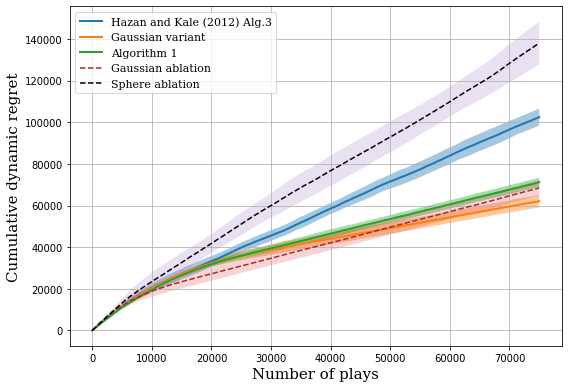

In [4]:
font = {'family': 'serif', 'size': 15}
x = np.arange(1, T+1)
plt.figure(figsize=(8, 5.5))
for kind in KINDS:
    m, s = curves[kind].mean(0), curves[kind].std(0)
    plt.plot(x, m, lw=2, label=LABELS[kind])
    plt.fill_between(x, m-s, m+s, alpha=0.40, linewidth=0)
plt.plot(x, abl['thresh'].mean(0), '--', color='brown', lw=1.5,
         label=ABL_PLOT['thresh'])
plt.fill_between(x, abl['thresh'].mean(0)-abl['thresh'].std(0), abl['thresh'].mean(0)+abl['thresh'].std(0), alpha=0.20, linewidth=0)
plt.plot(x, abl['sphere'].mean(0), '--', color='black', lw=1.5,
         label=ABL_PLOT['sphere'])
plt.fill_between(x, abl['sphere'].mean(0)-abl['sphere'].std(0), abl['sphere'].mean(0)+abl['sphere'].std(0), alpha=0.20, linewidth=0)
plt.xlabel('Number of plays', fontdict=font)
plt.ylabel('Cumulative dynamic regret', fontdict=font)
plt.legend(prop={'family': 'serif', 'size': 11}); plt.grid(True)
plt.tight_layout()
plt.savefig('bandit_regret_vs_plays.pdf', dpi=300, bbox_inches='tight')
plt.show()


In [5]:
"""
Static regret and iterate optimality gap, over SEEDS, at the hyperparameters
selected in cell 1 (main methods) and cell 2 (no-control-variate ablations).
"""
bsum = env._B.sum(axis=0)                       # sum_t b_t, from the precompute
best_fixed_total = (T*env.alpha*env.sqrt_w_all - env.masks @ bsum).min()
best_fixed_per_play = best_fixed_total / T
def prefix_best_fixed(env, T, chunk=5000):
    """min_S sum_{t<=t'} f_t(S) for every t' (static comparator of each prefix)."""
    cumB = np.cumsum(env._B[:T], axis=0)
    out = np.empty(T)
    for s in range(0, T, chunk):
        e = min(s + chunk, T)
        tt = np.arange(s + 1, e + 1)[:, None]
        vals = tt*env.alpha*env.sqrt_w_all[None, :] - cumB[s:e] @ env.masks.T
        out[s:e] = vals.min(axis=1)
    return out

prefix_best = prefix_best_fixed(env, T)

ABL_KINDS  = ['thresh_abl', 'sphere_abl']
ABL_SOURCE = {'thresh_abl': 'thresh', 'sphere_abl': 'sphere'}
ABL_LABELS = {'thresh_abl': 'ZO Gaussian (no CV)', 'sphere_abl': 'ZO Sphere (no CV)'}

static, gaps = {}, {}
for kind in KINDS:
    S_, G_ = [], []
    for s in SEEDS:
        pc, _, gap = run_instrumented(make_method(kind, params[kind], s),
                                      env, T, min_curve=mc)
        S_.append(np.cumsum(pc) - prefix_best); G_.append(gap)
    static[kind], gaps[kind] = np.asarray(S_), np.asarray(G_)
    f = static[kind][:, -1]
    print(f"{LABELS[kind]:14s} static = {f.mean():8.0f} +/- {f.std():6.0f}", flush=True)

for kind in ABL_KINDS:
    src = ABL_SOURCE[kind]
    S_, G_ = [], []
    for s in SEEDS:
        pc, _, gap = run_instrumented(make_method(src, abl_params[src], s, cv=False),
                                      env, T, min_curve=mc)
        S_.append(np.cumsum(pc - prefix_best)); G_.append(gap)
    static[kind], gaps[kind] = np.asarray(S_), np.asarray(G_)
    f = static[kind][:, -1]
    print(f"{ABL_LABELS[kind]:20s} static = {f.mean():8.0f} +/- {f.std():6.0f}", flush=True)


Hazan and Kale (2012) Alg.3 static =    90507 +/-   4068
Gaussian variant static =    50135 +/-   2975
Algorithm 1    static =    59251 +/-   2162
ZO Gaussian (no CV)  static =    56543 +/-   3707
ZO Sphere (no CV)    static =   126128 +/-  10205


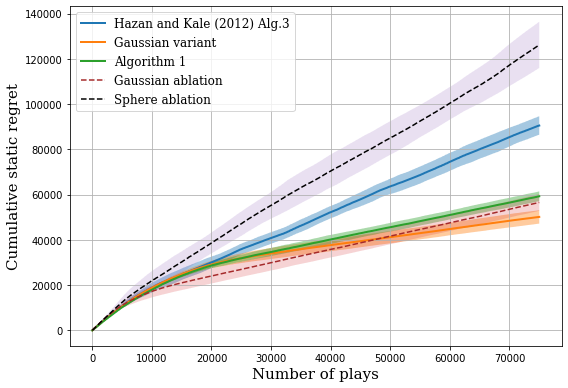

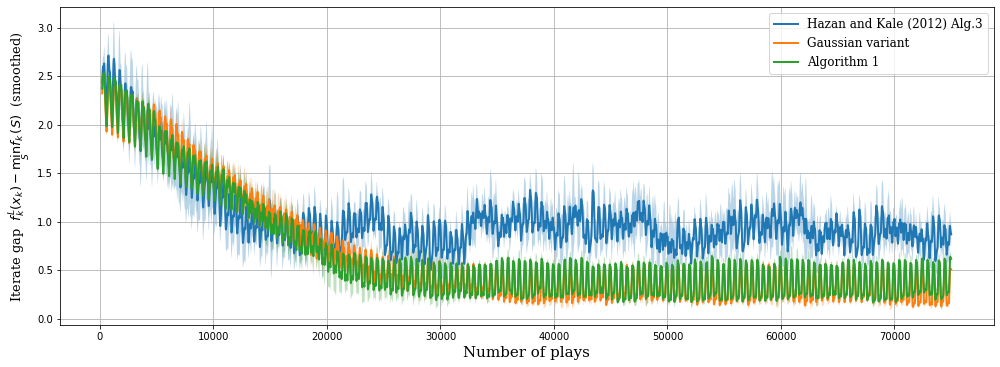

Hazan and Kale (2012) Alg.3 mean iterate gap (2nd half) = 0.920
Gaussian variant mean iterate gap (2nd half) = 0.325
Algorithm 1    mean iterate gap (2nd half) = 0.368
ZO Gaussian (no CV)  mean iterate gap (2nd half) = 0.387
ZO Sphere (no CV)    mean iterate gap (2nd half) = 1.389


In [6]:
font = {'family': 'serif', 'size': 15}
leg  = {'family': 'serif', 'size': 12}
x = np.arange(1, T+1)

# ============================ PLOT 1: static regret =========================
plt.figure(figsize=(8, 5.5))
for kind in KINDS:
    m, s = static[kind].mean(0), static[kind].std(0)
    plt.plot(x, m, lw=2, label=LABELS[kind])
    plt.fill_between(x, m-s, m+s, alpha=0.40, linewidth=0)
plt.plot(x, static['thresh_abl'].mean(0), '--', color='brown', lw=1.5,
         label=ABL_PLOT['thresh'])
plt.fill_between(x, static['thresh_abl'].mean(0)-static['thresh_abl'].std(0), static['thresh_abl'].mean(0)+static['thresh_abl'].std(0), alpha=0.20, linewidth=0)
plt.plot(x, static['sphere_abl'].mean(0), '--', color='black', lw=1.5,
         label=ABL_PLOT['sphere'])
plt.fill_between(x, static['sphere_abl'].mean(0)-static['sphere_abl'].std(0), static['sphere_abl'].mean(0)+static['sphere_abl'].std(0), alpha=0.20, linewidth=0)
plt.xlabel('Number of plays', fontdict=font)
plt.ylabel('Cumulative static regret', fontdict=font)
plt.legend(prop=leg); plt.grid(True)
plt.tight_layout()
plt.savefig('bandit_static_regret.pdf', dpi=300, bbox_inches='tight')
plt.show()

# ============================ PLOT 2: convergence history ===================
def smooth(a, w=1):
    return np.convolve(a, np.ones(w)/w, mode='valid')

W  = 200
xw = np.arange(W-1, T)          # correct alignment for mode='valid'
plt.figure(figsize=(14, 5.2))
for kind in KINDS:
    G = np.asarray([smooth(g, W) for g in gaps[kind]])
    m, s = G.mean(0), G.std(0)
    plt.plot(xw, m, lw=2, label=LABELS[kind])
    plt.fill_between(xw, m-s, m+s, alpha=0.30, linewidth=0)
# Gt = np.asarray([smooth(g, W) for g in gaps['thresh_abl']])
# plt.plot(xw, Gt.mean(0), '--', color='gray', lw=1.5,
#          label='ZO Gaussian, no control variate')
# Gs = np.asarray([smooth(g, W) for g in gaps['sphere_abl']])
# plt.plot(xw, Gs.mean(0), '--', color='black', lw=1.5,
#          label='ZO Sphere, no control variate')
plt.xlabel('Number of plays', fontdict=font)
plt.ylabel(r'Iterate gap  $f^L_k(x_k)-\min_S f_k(S)$  (smoothed)',
           fontdict={'family': 'serif', 'size': 13})
plt.legend(prop=leg); plt.grid(True)
plt.tight_layout()
plt.savefig('bandit_convergence_history.pdf', dpi=300, bbox_inches='tight')
plt.show()

for kind in KINDS:
    print(f"{LABELS[kind]:14s} mean iterate gap (2nd half) = "
          f"{gaps[kind][:, T//2:].mean():.3f}")
for kind in ABL_KINDS:
    print(f"{ABL_LABELS[kind]:20s} mean iterate gap (2nd half) = "
          f"{gaps[kind][:, T//2:].mean():.3f}")


In [8]:
# ===================== ONE SWEEP, BOTH PLOTS ===============================
# Raw dynamic regret vs P*, and the P*-attributable residual obtained by
# subtracting each method's near-stationary regret PER SEED (paired
# differencing: cancels the shared seed effect and tightens the error bars).
#
# REUSE=True keeps the cell-1 hyperparameters at every drift speed. This is
# faster and cleaner than re-tuning per period, which can itself manufacture
# non-monotonicity. Set REUSE=False for a robustness check.
REUSE = False

periods = [25, 50, 100, 1000, 2500, 5000, 10000, 20000]

env_stat = DriftingSubmodular(n=n, alpha=3.0, drift_amp=1.0,
                              drift_period=1e9, seed=7)
mc_stat  = env_stat.precompute(T)
P_anchor = path_length(env_stat, T)

anchor = {}
for kind in KINDS:
    c = (run_seeds(kind, params[kind], env_stat, mc_stat) if REUSE
         else best_over_seeds(kind, env_stat, mc_stat)[0])
    anchor[kind] = c[:, -1]                     # (len(SEEDS),)
print(f"anchor: P*={P_anchor:.1f}  " +
      "  ".join(f"{LABELS[k]}={anchor[k].mean():.0f}" for k in KINDS), flush=True)

Ps = [P_anchor]
F  = {k: [anchor[k]] for k in KINDS}
for period in periods:
    e   = DriftingSubmodular(n=n, alpha=3.0, drift_amp=1.0,
                             drift_period=float(period), seed=7)
    mce = e.precompute(T)
    Ps.append(path_length(e, T))
    for kind in KINDS:
        c = (run_seeds(kind, params[kind], e, mce) if REUSE
             else best_over_seeds(kind, e, mce)[0])
        F[kind].append(c[:, -1])
    print(f"period={period:6d}  P*={Ps[-1]:8.1f}  " +
          "  ".join(f"{LABELS[k]}={F[k][-1].mean():8.0f}+/-{F[k][-1].std():5.0f}"
                    for k in KINDS), flush=True)

order = np.argsort(Ps)
Pa = np.array(Ps)[order]


anchor: P*=0.0  Hazan and Kale (2012) Alg.3=56564  Gaussian variant=43083  Algorithm 1=54901
period=    25  P*= 18193.5  Hazan and Kale (2012) Alg.3=  106333+/- 3782  Gaussian variant=   62286+/- 2418  Algorithm 1=   73350+/- 2227
period=    50  P*=  9096.7  Hazan and Kale (2012) Alg.3=  107741+/- 3226  Gaussian variant=   62705+/- 1967  Algorithm 1=   72100+/- 2065
period=   100  P*=  4987.7  Hazan and Kale (2012) Alg.3=  108000+/- 4800  Gaussian variant=   62044+/- 1763  Algorithm 1=   71581+/-  966
period=  1000  P*=   498.8  Hazan and Kale (2012) Alg.3=  103641+/- 3930  Gaussian variant=   62043+/- 2480  Algorithm 1=   71142+/- 2776
period=  2500  P*=   199.5  Hazan and Kale (2012) Alg.3=   94852+/- 5529  Gaussian variant=   59538+/- 1378  Algorithm 1=   70574+/- 2036
period=  5000  P*=    99.8  Hazan and Kale (2012) Alg.3=   85331+/- 4794  Gaussian variant=   56349+/- 1412  Algorithm 1=   70425+/- 2557
period= 10000  P*=    46.6  Hazan and Kale (2012) Alg.3=   73418+/- 4542  Gauss

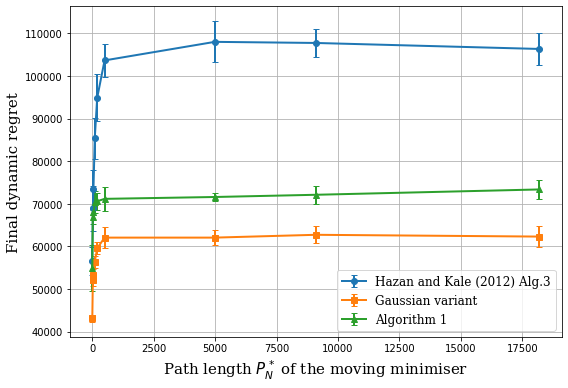

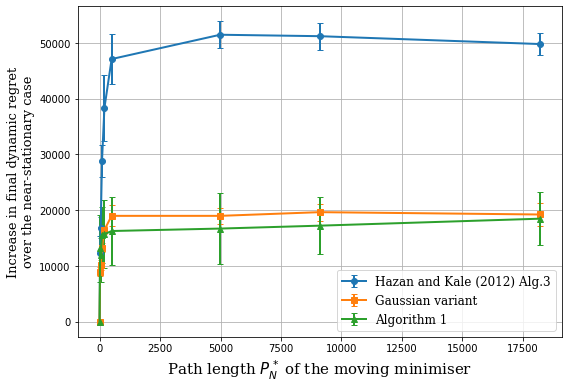

In [9]:
mk = {'hazan': 'o-', 'thresh': 's-', 'sphere': '^-'}

# ---- PLOT 1: raw dynamic regret vs P* --------------------------------------
plt.figure(figsize=(8, 5.5))
for kind in KINDS:
    A = np.array(F[kind])[order]                # (points, seeds)
    plt.errorbar(Pa, A.mean(1), yerr=A.std(1), fmt=mk[kind], lw=2,
                 capsize=3, label=LABELS[kind])
plt.xlabel(r'Path length $P^*_N$ of the moving minimiser', fontdict=font)
plt.ylabel('Final dynamic regret', fontdict=font)
plt.legend(prop={'family': 'serif', 'size': 12}); plt.grid(True)
plt.tight_layout()
plt.savefig('bandit_regret_vs_pathlength.pdf', dpi=300, bbox_inches='tight')
plt.show()

# ---- PLOT 2: P*-attributable residual (paired per seed) --------------------
plt.figure(figsize=(8, 5.5))
for kind in KINDS:
    R = np.array(F[kind])[order] - anchor[kind][None, :]
    plt.errorbar(Pa, R.mean(1), yerr=R.std(1), fmt=mk[kind], lw=2,
                 capsize=3, label=LABELS[kind])
plt.xlabel(r'Path length $P^*_N$ of the moving minimiser', fontdict=font)
plt.ylabel('Increase in final dynamic regret\nover the near-stationary case',
           fontdict={'family': 'serif', 'size': 13})
plt.legend(prop={'family': 'serif', 'size': 12}); plt.grid(True)
plt.tight_layout()
plt.savefig('bandit_regret_residual_vs_pathlength.pdf', dpi=300, bbox_inches='tight')
plt.show()
